<a href="https://colab.research.google.com/github/Bassma-Chemaou/projet6-3d/blob/main/notebooks/03_vae_nuages_de_points.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os, sys, time, random
if not os.path.exists("/content/projet6-3d"):
    !git clone https://github.com/Bassma-Chemaou/projet6-3d.git /content/projet6-3d
%cd /content/projet6-3d
!git pull -q
sys.path.insert(0, "/content/projet6-3d")

import numpy as np, torch, torch.nn as nn
import matplotlib.pyplot as plt, pandas as pd
from pathlib import Path
from src.losses import chamfer_batch, kl_divergence
from src.metrics import pairwise_cd, gen_metrics
from src.data.datasets import load_processed, augment

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
dev = torch.device("cuda")
torch.cuda.set_per_process_memory_fraction(
    min(1.0, 12 / (torch.cuda.get_device_properties(0).total_memory / 1e9)))   # limite 12 Go

D = Path("/content/drive/MyDrive/projet6-3d/processed")
CK = Path("/content/drive/MyDrive/projet6-3d/checkpoints"); CK.mkdir(parents=True, exist_ok=True)
X, Y, cats = load_processed(D)
print({s: tuple(X[s].shape) for s in X}, cats, "|", torch.cuda.get_device_name(0))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/projet6-3d
{'train': (1353, 2048, 3), 'val': (239, 2048, 3), 'test': (400, 2048, 3)} ['chair', 'table', 'sofa', 'bed'] | Tesla T4


In [ ]:
class PointNetVAE(nn.Module):
    """Encodeur PointNet -> (mu, logvar) ; décodeur MLP. n_classes > 0 : version conditionnelle (CVAE)."""
    def __init__(self, n_points=2048, latent=128, n_classes=0):
        super().__init__()
        ch, layers = [3, 64, 128, 256, 512], []
        for i in range(4):
            layers += [nn.Conv1d(ch[i], ch[i + 1], 1), nn.BatchNorm1d(ch[i + 1]), nn.ReLU()]
        self.enc = nn.Sequential(*layers)
        self.fc_mu, self.fc_logvar = nn.Linear(512, latent), nn.Linear(512, latent)
        self.dec = nn.Sequential(nn.Linear(latent + n_classes, 512), nn.ReLU(),
                                 nn.Linear(512, 1024), nn.ReLU(),
                                 nn.Linear(1024, n_points * 3))
        self.n, self.n_classes, self.latent = n_points, n_classes, latent

    def encode(self, x):
        h = self.enc(x.transpose(1, 2)).max(2)[0]
        return self.fc_mu(h), self.fc_logvar(h)

    def decode(self, z, y=None):
        if self.n_classes:
            z = torch.cat([z, nn.functional.one_hot(y, self.n_classes).float()], 1)
        return self.dec(z).view(-1, self.n, 3)

    def forward(self, x, y=None):
        mu, logvar = self.encode(x)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)
        return self.decode(z, y), mu, logvar


@torch.no_grad()
def eval_vae(model, Xs, Ys, n_classes=0, bs=64):
    """Chamfer de reconstruction (avec mu, sans tirage) et KL moyens sur un ensemble."""
    model.eval(); r_tot = k_tot = 0
    for i in range(0, len(Xs), bs):
        xb = Xs[i:i + bs].to(dev)
        yb = torch.as_tensor(Ys[i:i + bs]).long().to(dev) if n_classes else None
        mu, logvar = model.encode(xb)
        r_tot += chamfer_batch(model.decode(mu, yb), xb).sum().item()
        k_tot += kl_divergence(mu, logvar).item() * len(xb)
    return r_tot / len(Xs), k_tot / len(Xs)


def train_vae(name, latent=128, beta_max=1e-3, epochs=300, warmup=100, lr=1e-3, bs=32, n_classes=0):
    model = PointNetVAE(2048, latent, n_classes).to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=lr * 0.01)
    Xtr, Ytr = X["train"], torch.from_numpy(Y["train"]).long()
    hist = {"rec": [], "kl": [], "val_rec": [], "val_kl": []}
    best, t0 = 1e9, time.time()
    torch.cuda.reset_peak_memory_stats()
    for ep in range(1, epochs + 1):
        beta = beta_max * min(1.0, ep / warmup)                  # annealing du KL
        model.train(); perm = torch.randperm(len(Xtr)); r_tot = k_tot = 0
        for i in range(0, len(perm), bs):
            ids = perm[i:i + bs]
            if len(ids) < 2: continue                            # BatchNorm exige au moins 2 éléments
            xb = augment(Xtr[ids].to(dev))
            yb = Ytr[ids].to(dev) if n_classes else None
            rec, mu, logvar = model(xb, yb)
            r, k = chamfer_batch(rec, xb).mean(), kl_divergence(mu, logvar)
            loss = r + beta * k
            opt.zero_grad(); loss.backward(); opt.step()
            r_tot += r.item() * len(ids); k_tot += k.item() * len(ids)
        sched.step()
        vr, vk = eval_vae(model, X["val"], Y["val"], n_classes)
        for key, v in zip(hist, (r_tot / len(perm), k_tot / len(perm), vr, vk)): hist[key].append(v)
        score = vr + beta_max * vk                               # critère fixe (β final) pour comparer les époques
        if ep >= warmup and score < best:
            best = score; torch.save(model.state_dict(), CK / f"{name}_best.pth")
        if ep % 10 == 0 or ep == 1:
            print(f"ép {ep:3d} | β {beta:.1e} | rec {hist['rec'][-1]:.5f} KL {hist['kl'][-1]:6.2f} | "
                  f"val rec {vr:.5f} KL {vk:6.2f} | meilleur {best:.5f} | {time.time()-t0:.0f} s")
    stats = {"params": sum(p.numel() for p in model.parameters()),
             "minutes": (time.time() - t0) / 60, "vram": torch.cuda.max_memory_allocated() / 1e9}
    model.load_state_dict(torch.load(CK / f"{name}_best.pth")); model.eval()
    print(f"\nParamètres : {stats['params']:,} | durée : {stats['minutes']:.1f} min | VRAM max : {stats['vram']:.2f} Go")
    return model, hist, stats

In [ ]:
vae, h_vae, s_vae = train_vae("vae_points", latent=128, beta_max=1e-3, epochs=300, warmup=100)

ép   1 | β 1.0e-05 | rec 0.17564 KL  14.12 | val rec 0.06256 KL   9.77 | meilleur 1000000000.00000 | 4 s
ép  10 | β 1.0e-04 | rec 0.01706 KL   4.33 | val rec 0.01518 KL   4.08 | meilleur 1000000000.00000 | 40 s
ép  20 | β 2.0e-04 | rec 0.01682 KL   3.58 | val rec 0.01189 KL   3.33 | meilleur 1000000000.00000 | 79 s
ép  30 | β 3.0e-04 | rec 0.01036 KL   2.44 | val rec 0.01019 KL   2.26 | meilleur 1000000000.00000 | 118 s
ép  40 | β 4.0e-04 | rec 0.01033 KL   2.02 | val rec 0.01164 KL   2.12 | meilleur 1000000000.00000 | 158 s
ép  50 | β 5.0e-04 | rec 0.00912 KL   1.75 | val rec 0.00887 KL   1.73 | meilleur 1000000000.00000 | 198 s
ép  60 | β 6.0e-04 | rec 0.00948 KL   1.71 | val rec 0.00874 KL   1.54 | meilleur 1000000000.00000 | 238 s
ép  70 | β 7.0e-04 | rec 0.00818 KL   1.38 | val rec 0.00835 KL   1.34 | meilleur 1000000000.00000 | 278 s
ép  80 | β 8.0e-04 | rec 0.00826 KL   1.24 | val rec 0.00815 KL   1.25 | meilleur 1000000000.00000 | 318 s
ép  90 | β 9.0e-04 | rec 0.00777 KL   1.0

Chamfer de reconstruction (test) : 0.00632   | KL (test) : 0.69   [baseline AE : 0.00684]


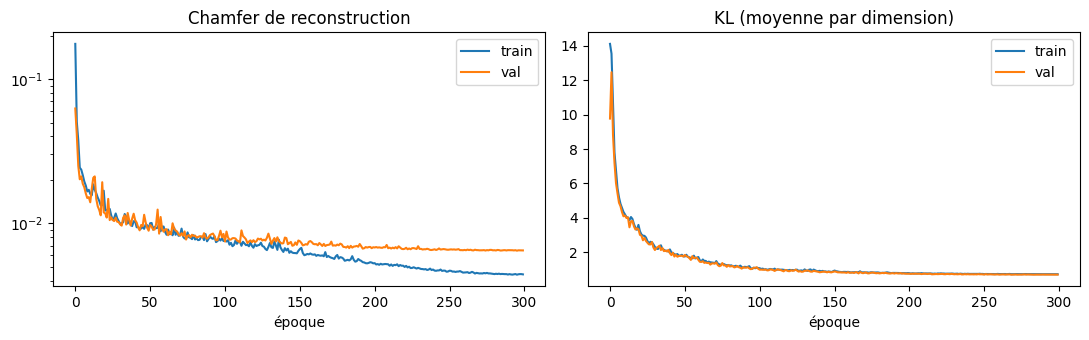

In [ ]:
cd_test, kl_test = eval_vae(vae, X["test"], Y["test"])
print(f"Chamfer de reconstruction (test) : {cd_test:.5f}   | KL (test) : {kl_test:.2f}   [baseline AE : 0.00684]")

fig_curves, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(h_vae["rec"], label="train"); ax[0].plot(h_vae["val_rec"], label="val")
ax[0].set_yscale("log"); ax[0].set_title("Chamfer de reconstruction"); ax[0].set_xlabel("époque"); ax[0].legend()
ax[1].plot(h_vae["kl"], label="train"); ax[1].plot(h_vae["val_kl"], label="val")
ax[1].set_title("KL (moyenne par dimension)"); ax[1].set_xlabel("époque"); ax[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
@torch.no_grad()
def generate(model, n, seed=SEED, y=None):
    """Tire z ~ N(0, I) avec une graine fixe (identique pour tous les modèles) et décode."""
    model.eval()
    z = torch.randn(n, model.latent, generator=torch.Generator().manual_seed(seed)).to(dev)
    out = [model.decode(z[i:i + 100], None if y is None else y[i:i + 100].to(dev)).cpu()
           for i in range(0, n, 100)]
    return torch.cat(out)

N_GEN = len(X["test"])                                       # autant de formes générées que de formes de test
t0 = time.time(); G_full = generate(vae, 1000); t_gen = time.time() - t0   # durée pour 1 000 formes
G_full = G_full[:N_GEN]
sel = torch.randperm(2048, generator=torch.Generator().manual_seed(SEED))[:1024]
G, R, T = G_full[:, sel], X["test"][:, :1024], X["train"][:, :1024]
print("Coordonnées générées : min", G_full.min().item(), "max", G_full.max().item())

t0 = time.time()
m_vae = gen_metrics(G, R)
print("VAE :", {k: round(v, 4) for k, v in m_vae.items()},
      "| référence train/test : MMD-CD 0.0151, COV 0.545, 1-NNA 0.5525")

d_gen = pairwise_cd(G, T).min(1)[0]          # forme générée -> forme du train la plus proche
d_real = pairwise_cd(R, T).min(1)[0]         # référence : forme de test -> forme du train la plus proche
print(f"Distance au train : générées {d_gen.mean():.5f} (min {d_gen.min():.5f}) | "
      f"formes de test (référence) {d_real.mean():.5f} (min {d_real.min():.5f}) | {time.time()-t0:.0f} s")
print(f"Génération de 1 000 formes : {t_gen:.2f} s")

Coordonnées générées : min -0.9394150972366333 max 0.9214079976081848
VAE : {'MMD-CD': 0.0505, 'COV': 0.0475, '1-NNA': 0.995} | référence train/test : MMD-CD 0.0151, COV 0.545, 1-NNA 0.5525
Distance au train : générées 0.01438 (min 0.00248) | formes de test (référence) 0.01268 (min 0.00277) | 204 s
Génération de 1 000 formes : 0.03 s


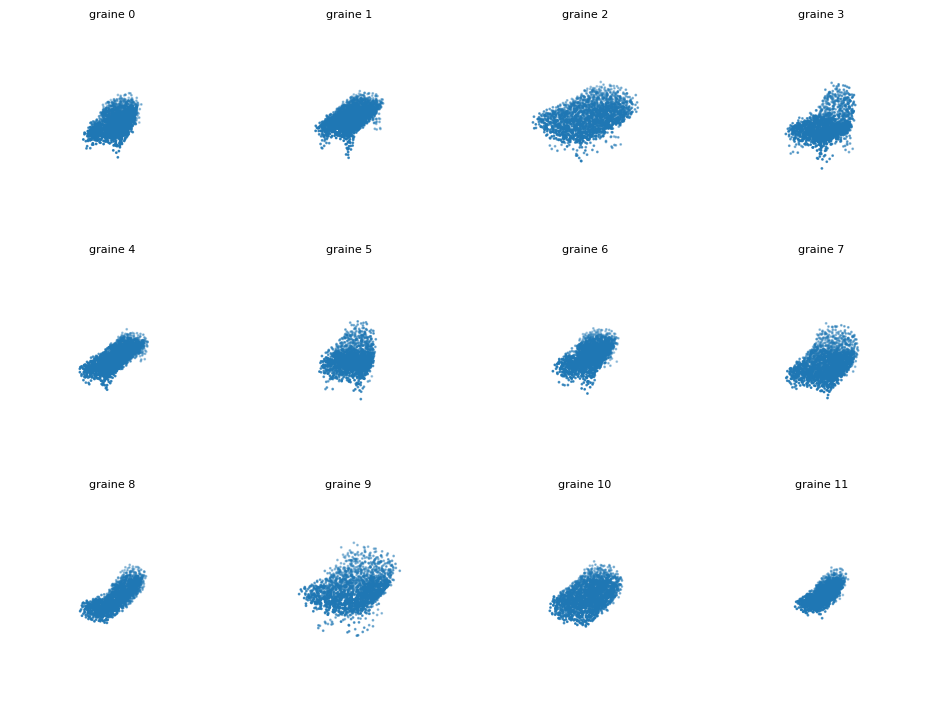

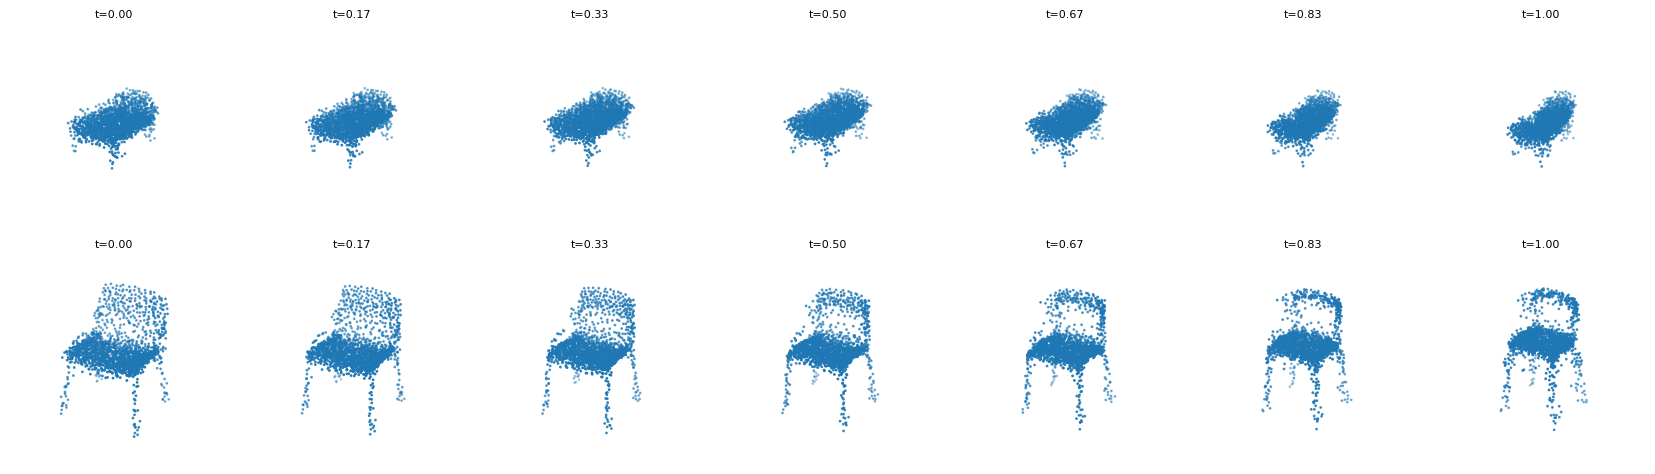

In [ ]:
def show_clouds(clouds, titles=None, ncols=4, size=1):
    nrows = (len(clouds) + ncols - 1) // ncols
    fig = plt.figure(figsize=(2.4 * ncols, 2.4 * nrows))
    for i, p in enumerate(clouds):
        p = p.cpu().numpy() if torch.is_tensor(p) else p
        ax = fig.add_subplot(nrows, ncols, i + 1, projection="3d")
        ax.scatter(p[:, 0], p[:, 1], p[:, 2], s=size)
        ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_zlim(-1, 1)
        ax.set_box_aspect((1, 1, 1)); ax.set_axis_off()
        if titles: ax.set_title(titles[i], fontsize=8)
    plt.tight_layout(); return fig

fig_gen = show_clouds(list(G_full[:12]), [f"graine {i}" for i in range(12)], ncols=4); plt.show()

@torch.no_grad()
def interpolate(model, z1, z2, steps=7):
    z = torch.stack([(1 - t) * z1 + t * z2 for t in torch.linspace(0, 1, steps)]).to(dev)
    return model.decode(z).cpu()

# (a) deux codes tirés au hasard
zz = torch.randn(2, vae.latent, generator=torch.Generator().manual_seed(7))
row_a = interpolate(vae, zz[0], zz[1])
# (b) entre les codes (mu) de deux chaises du test
with torch.no_grad():
    c = np.where(Y["test"] == 0)[0][:2]
    mu_c, _ = vae.encode(X["test"][c].to(dev))
row_b = interpolate(vae, mu_c[0].cpu(), mu_c[1].cpu())
fig_interp = show_clouds(list(row_a) + list(row_b), [f"t={t:.2f}" for t in np.linspace(0, 1, 7)] * 2, ncols=7)
plt.show()

In [ ]:
res = pd.DataFrame([{"Modèle": "VAE points", "Latent": 128, "Points": 2048, "CD test": cd_test, **m_vae,
                     "Params": s_vae["params"], "1000 formes (s)": round(t_gen, 2),
                     "Durée (min)": round(s_vae["minutes"], 1), "VRAM max (Go)": round(s_vae["vram"], 2),
                     "Dist. au train": float(d_gen.mean())}])
print(res.T)

os.makedirs("/content/results", exist_ok=True)
fig_curves.savefig("/content/results/vae_courbes.png", dpi=130, bbox_inches="tight")
fig_gen.savefig("/content/results/vae_generation.png", dpi=130, bbox_inches="tight")
fig_interp.savefig("/content/results/vae_interpolation.png", dpi=130, bbox_inches="tight")
res.to_csv("/content/results/tableau_A_vae.csv", index=False)
res.to_csv("/content/drive/MyDrive/projet6-3d/resultats_vae.csv", index=False)

from google.colab import files
for f in ["vae_courbes.png", "vae_generation.png", "vae_interpolation.png", "tableau_A_vae.csv"]:
    files.download(f"/content/results/{f}")

                          0
Modèle           VAE points
Latent                  128
Points                 2048
CD test            0.006321
MMD-CD             0.050528
COV                  0.0475
1-NNA                 0.995
Params              7195392
1000 formes (s)        0.03
Durée (min)            20.0
VRAM max (Go)          2.35
Dist. au train     0.014382


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

ép   1 | β 1.0e-05 | rec 0.06206 KL   4.79 | val rec 0.04786 KL   3.66 | meilleur 1000000000.00000 | 4 s
ép  10 | β 1.0e-04 | rec 0.01281 KL   3.21 | val rec 0.01199 KL   3.02 | meilleur 1000000000.00000 | 40 s
ép  20 | β 2.0e-04 | rec 0.00996 KL   2.45 | val rec 0.01102 KL   2.29 | meilleur 1000000000.00000 | 80 s
ép  30 | β 3.0e-04 | rec 0.00974 KL   2.20 | val rec 0.00933 KL   2.01 | meilleur 1000000000.00000 | 120 s
ép  40 | β 4.0e-04 | rec 0.00826 KL   1.70 | val rec 0.00871 KL   1.61 | meilleur 1000000000.00000 | 160 s
ép  50 | β 5.0e-04 | rec 0.00767 KL   1.47 | val rec 0.00853 KL   1.41 | meilleur 1000000000.00000 | 200 s
ép  60 | β 6.0e-04 | rec 0.00807 KL   1.35 | val rec 0.00821 KL   1.32 | meilleur 1000000000.00000 | 240 s
ép  70 | β 7.0e-04 | rec 0.00761 KL   1.22 | val rec 0.00830 KL   1.22 | meilleur 1000000000.00000 | 280 s
ép  80 | β 8.0e-04 | rec 0.00751 KL   1.12 | val rec 0.00783 KL   1.08 | meilleur 1000000000.00000 | 320 s
ép  90 | β 9.0e-04 | rec 0.00744 KL   1.1

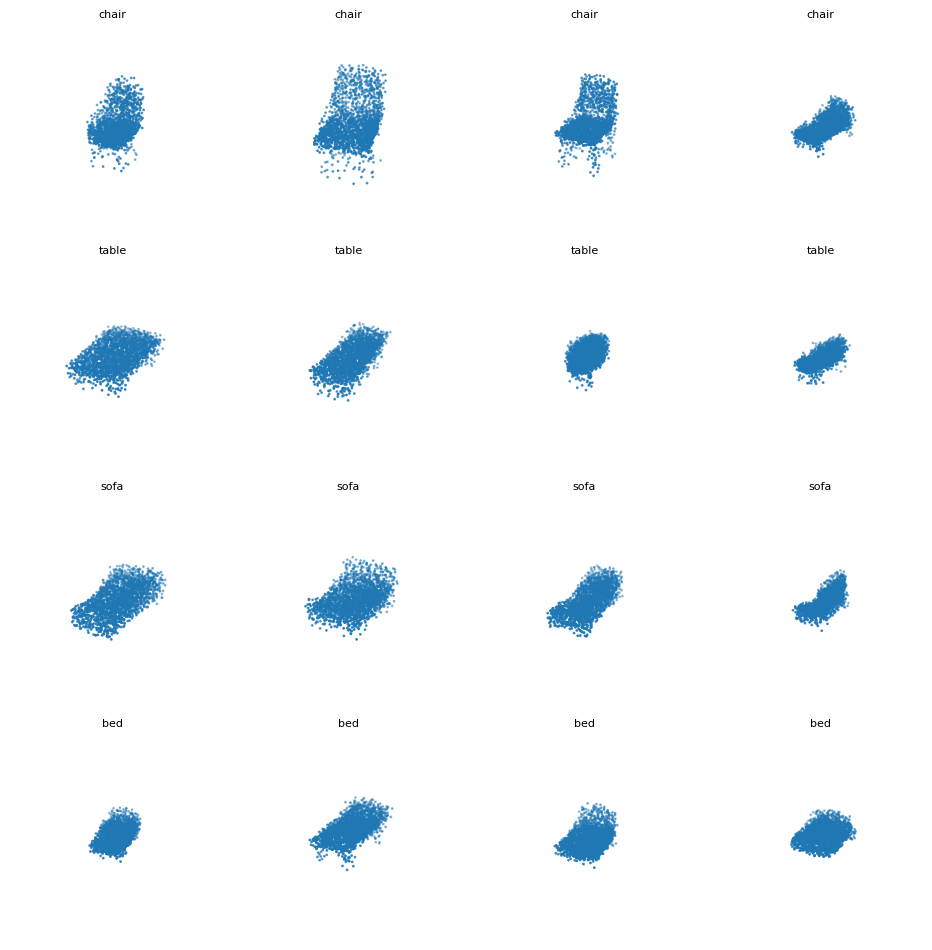

In [ ]:
cvae, h_cvae, s_cvae = train_vae("cvae_points", n_classes=len(cats))
y_gen = torch.from_numpy(Y["test"]).long()                   # 100 formes par catégorie, comme le test
Gc_full = generate(cvae, N_GEN, y=y_gen)
m_cvae = gen_metrics(Gc_full[:, sel], R)
print("CVAE :", {k: round(v, 4) for k, v in m_cvae.items()}, "| CD test :", eval_vae(cvae, X["test"], Y["test"], len(cats))[0])
show_clouds([Gc_full[np.where(Y["test"] == c)[0][j]] for c in range(len(cats)) for j in range(4)],
            [cats[c] for c in range(len(cats)) for _ in range(4)], ncols=4); plt.show()

Dimensions actives (KL > 0.1) : 123 / 128
10 plus grandes KL par dimension : [6.68 6.48 5.12 2.76 2.75 2.18 2.03 2.01 1.98 1.85]
écart-type de mu par dimension : min 0.229 | médiane 0.470 | max 2.787
sigma moyen du posterior : 0.552
(a) posterior de formes de test : {'MMD-CD': 0.0097, 'COV': 0.6575, '1-NNA': 0.48}
(b) gaussienne ajustée aux codes   : {'MMD-CD': 0.0177, 'COV': 0.355, '1-NNA': 0.8438}


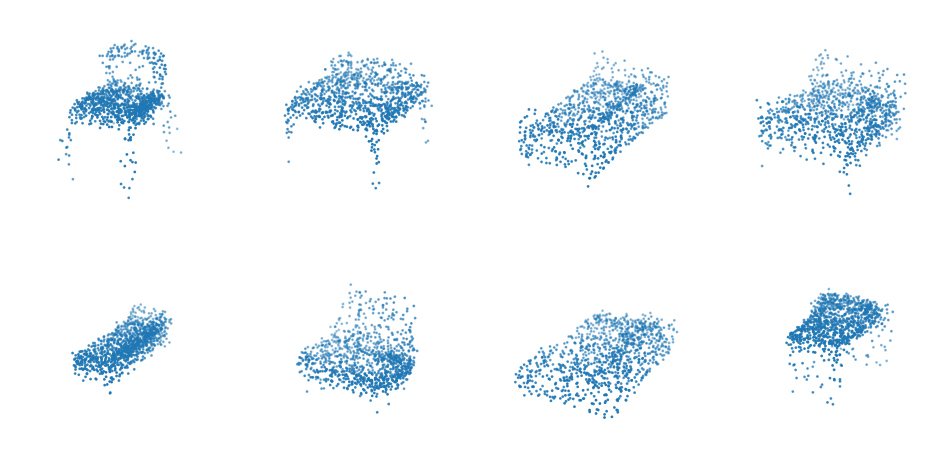

In [ ]:
@torch.no_grad()
def posterior_stats(model, Xs, bs=64):
    model.eval(); mus, lvs = [], []
    for i in range(0, len(Xs), bs):
        mu, lv = model.encode(Xs[i:i + bs].to(dev)); mus.append(mu.cpu()); lvs.append(lv.cpu())
    return torch.cat(mus), torch.cat(lvs)

@torch.no_grad()
def decode_z(model, z):
    return torch.cat([model.decode(z[i:i + 100].to(dev)).cpu() for i in range(0, len(z), 100)])

mu, lv = posterior_stats(vae, X["train"])
kl_dim = (0.5 * (mu.pow(2) + lv.exp() - lv - 1)).mean(0)
print("Dimensions actives (KL > 0.1) :", int((kl_dim > 0.1).sum()), "/", vae.latent)
print("10 plus grandes KL par dimension :", kl_dim.sort(descending=True)[0][:10].numpy().round(2))
print("écart-type de mu par dimension : min %.3f | médiane %.3f | max %.3f" %
      (mu.std(0).min(), mu.std(0).median(), mu.std(0).max()))
print("sigma moyen du posterior : %.3f" % lv.mul(0.5).exp().mean())

# (a) codes issus de vraies formes de test : plafond de ce que sait faire le décodeur
mu_t, lv_t = posterior_stats(vae, X["test"])
Ga = decode_z(vae, mu_t + torch.randn_like(mu_t) * torch.exp(0.5 * lv_t))[:, sel]
print("(a) posterior de formes de test :", {k: round(v, 4) for k, v in gen_metrics(Ga, R).items()})

# (b) tirage dans une gaussienne ajustée aux codes réels (au lieu de N(0, I))
torch.manual_seed(SEED)
C = torch.cov(mu.T) + 1e-4 * torch.eye(vae.latent)
z_b = torch.distributions.MultivariateNormal(mu.mean(0), covariance_matrix=C).sample((N_GEN,))
Gb = decode_z(vae, z_b)[:, sel]
print("(b) gaussienne ajustée aux codes   :", {k: round(v, 4) for k, v in gen_metrics(Gb, R).items()})
show_clouds(list(Gb[:8]), ncols=4); plt.show()

ép   1 | β 1.7e-04 | rec 0.08783 KL   6.54 | val rec 0.05917 KL   4.39 | meilleur 1000000000.00000 | 4 s
ép  10 | β 1.7e-03 | rec 0.01370 KL   1.17 | val rec 0.01188 KL   1.16 | meilleur 1000000000.00000 | 40 s
ép  20 | β 3.3e-03 | rec 0.01214 KL   0.67 | val rec 0.01122 KL   0.68 | meilleur 1000000000.00000 | 79 s
ép  30 | β 5.0e-03 | rec 0.01135 KL   0.48 | val rec 0.01329 KL   0.52 | meilleur 1000000000.00000 | 119 s
ép  40 | β 6.7e-03 | rec 0.01125 KL   0.39 | val rec 0.01267 KL   0.38 | meilleur 1000000000.00000 | 159 s
ép  50 | β 8.3e-03 | rec 0.01130 KL   0.33 | val rec 0.01135 KL   0.30 | meilleur 1000000000.00000 | 199 s
ép  60 | β 1.0e-02 | rec 0.01055 KL   0.26 | val rec 0.01126 KL   0.25 | meilleur 0.01379 | 239 s
ép  70 | β 1.0e-02 | rec 0.01000 KL   0.23 | val rec 0.01186 KL   0.24 | meilleur 0.01175 | 279 s
ép  80 | β 1.0e-02 | rec 0.00955 KL   0.22 | val rec 0.00960 KL   0.21 | meilleur 0.01118 | 319 s
ép  90 | β 1.0e-02 | rec 0.01038 KL   0.24 | val rec 0.01041 KL   0.

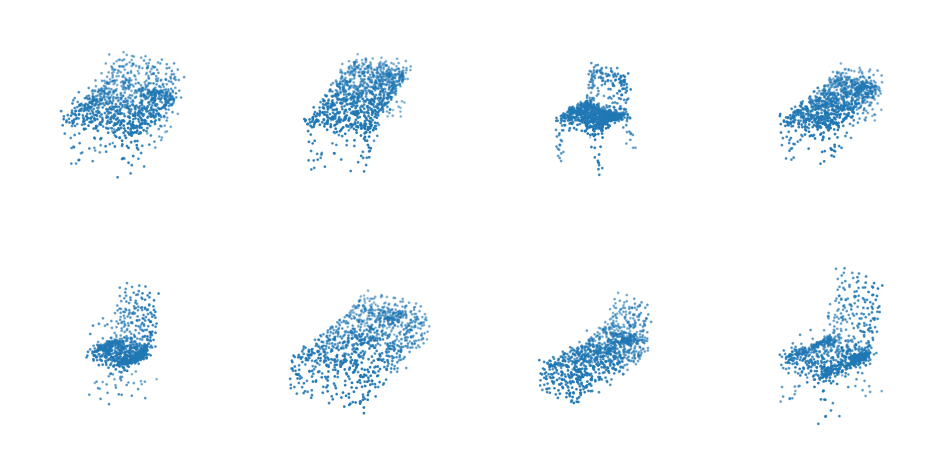

ép   1 | β 5.0e-04 | rec 0.11591 KL   9.34 | val rec 0.06025 KL   4.47 | meilleur 1000000000.00000 | 4 s
ép  10 | β 5.0e-03 | rec 0.01735 KL   0.70 | val rec 0.01460 KL   0.67 | meilleur 1000000000.00000 | 40 s
ép  20 | β 1.0e-02 | rec 0.01526 KL   0.38 | val rec 0.02218 KL   0.41 | meilleur 1000000000.00000 | 80 s
ép  30 | β 1.5e-02 | rec 0.01332 KL   0.25 | val rec 0.02106 KL   0.24 | meilleur 1000000000.00000 | 120 s
ép  40 | β 2.0e-02 | rec 0.01252 KL   0.19 | val rec 0.02229 KL   0.18 | meilleur 1000000000.00000 | 160 s
ép  50 | β 2.5e-02 | rec 0.01380 KL   0.18 | val rec 0.01695 KL   0.18 | meilleur 1000000000.00000 | 200 s
ép  60 | β 3.0e-02 | rec 0.01160 KL   0.13 | val rec 0.01812 KL   0.12 | meilleur 0.02181 | 240 s
ép  70 | β 3.0e-02 | rec 0.01130 KL   0.11 | val rec 0.01282 KL   0.11 | meilleur 0.01602 | 280 s
ép  80 | β 3.0e-02 | rec 0.01105 KL   0.11 | val rec 0.01215 KL   0.10 | meilleur 0.01523 | 320 s
ép  90 | β 3.0e-02 | rec 0.01038 KL   0.11 | val rec 0.01303 KL   0.

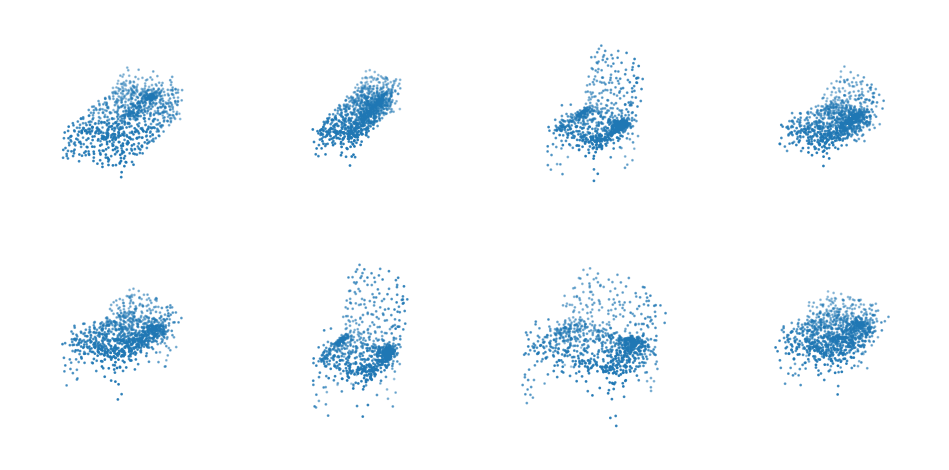

In [ ]:
def eval_gen(model, n_classes=0):
    cd = eval_vae(model, X["test"], Y["test"], n_classes)[0]
    Gg = generate(model, N_GEN)[:, sel]
    return {"CD test": cd, **gen_metrics(Gg, R)}, Gg

sweep = {}
for beta in [1e-2, 3e-2]:
    mdl, h, s = train_vae(f"vae_points_beta{beta:g}", beta_max=beta, epochs=200, warmup=60)
    r, Gg = eval_gen(mdl)
    sweep[beta] = (r, s)
    print(f"\n>>> β = {beta:g} :", {k: round(v, 4) for k, v in r.items()})
    show_clouds(list(Gg[:8]), ncols=4); plt.show()

{'β': '1e-3', 'prior': 'gaussienne ajustée', 'MMD-CD': 0.0177, 'COV': 0.355, '1-NNA': 0.8438}
{'β': '1e-3', 'prior': 'GMM diag k=8', 'MMD-CD': 0.0168, 'COV': 0.34, '1-NNA': 0.7663}
{'β': '1e-2', 'prior': 'gaussienne ajustée', 'MMD-CD': 0.0172, 'COV': 0.3775, '1-NNA': 0.8238}
{'β': '1e-2', 'prior': 'GMM diag k=8', 'MMD-CD': 0.0176, 'COV': 0.3525, '1-NNA': 0.8225}
{'β': '3e-2', 'prior': 'gaussienne ajustée', 'MMD-CD': 0.0177, 'COV': 0.3375, '1-NNA': 0.8562}
{'β': '3e-2', 'prior': 'GMM diag k=8', 'MMD-CD': 0.0189, 'COV': 0.34, '1-NNA': 0.8687}

    β              prior  MMD-CD    COV  1-NNA
1e-3 gaussienne ajustée  0.0177 0.3550 0.8438
1e-3       GMM diag k=8  0.0168 0.3400 0.7663
1e-2 gaussienne ajustée  0.0172 0.3775 0.8238
1e-2       GMM diag k=8  0.0176 0.3525 0.8225
3e-2 gaussienne ajustée  0.0177 0.3375 0.8562
3e-2       GMM diag k=8  0.0189 0.3400 0.8687

Meilleure configuration : 1e-3 GMM diag k=8


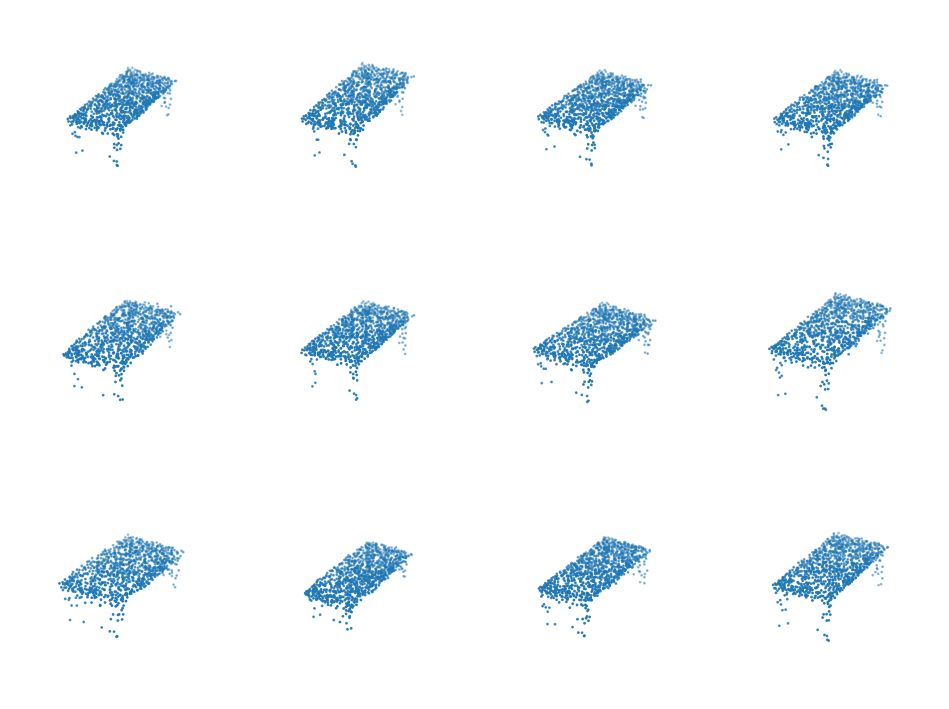

Distance au train : générées 0.01094 (min 0.00320) | formes de test (référence) 0.01268 (min 0.00277)


In [ ]:
from sklearn.mixture import GaussianMixture

def load_vae(name):
    m = PointNetVAE(2048, 128).to(dev)
    m.load_state_dict(torch.load(CK / f"{name}_best.pth")); m.eval(); return m

def eval_posthoc(model, kind="gauss", k=1, seed=SEED):
    mu_tr, _ = posterior_stats(model, X["train"])               # codes des formes du TRAIN uniquement
    if kind == "gauss":
        torch.manual_seed(seed)
        C = torch.cov(mu_tr.T) + 1e-4 * torch.eye(model.latent)
        z = torch.distributions.MultivariateNormal(mu_tr.mean(0), covariance_matrix=C).sample((N_GEN,))
    else:
        gm = GaussianMixture(n_components=k, covariance_type="diag", reg_covar=1e-4,
                             random_state=seed).fit(mu_tr.numpy())
        z = torch.from_numpy(gm.sample(N_GEN)[0]).float()
    Gz = decode_z(model, z)
    return Gz, gen_metrics(Gz[:, sel], R)

rows, gens = [], {}
for name, beta in [("vae_points", "1e-3"), ("vae_points_beta0.01", "1e-2"), ("vae_points_beta0.03", "3e-2")]:
    m = load_vae(name)
    for kind, k in [("gauss", 1), ("gmm", 8)]:
        Gz, met = eval_posthoc(m, kind, k)
        label = "gaussienne ajustée" if kind == "gauss" else f"GMM diag k={k}"
        rows.append({"β": beta, "prior": label, **{kk: round(v, 4) for kk, v in met.items()}})
        gens[(beta, label)] = Gz
        print(rows[-1])

tab_post = pd.DataFrame(rows); print("\n", tab_post.to_string(index=False))

# meilleure configuration (1-NNA le plus bas) : formes générées + distance au train
best = tab_post.sort_values("1-NNA").iloc[0]
Gbest = gens[(best["β"], best["prior"])]
print("\nMeilleure configuration :", best["β"], best["prior"])
show_clouds(list(Gbest[:12, sel]), ncols=4); plt.show()
d_gen = pairwise_cd(Gbest[:, sel], T).min(1)[0]
print(f"Distance au train : générées {d_gen.mean():.5f} (min {d_gen.min():.5f}) | "
      f"formes de test (référence) 0.01268 (min 0.00277)")